---
title: "2.1 Геоөгөгдлийн интерполяци"
---

{button}`▶ Open in Colab <https://colab.research.google.com/github/num-sgas/learn-num-sgas/blob/main/courses/geostatistics/02-spatial-prediction/01-simple-spatial-predictions.ipynb>`

You will start your journey into the world of geological modeling by exploring how to make spatial predictions using a linear model.

At the end of this notebook, you should be able to:
 1. Explain how to make spatial predictions from punctual data such as well data.
 2. Use interpolation methods to solve simple geomodeling problems.

:::{admonition} Instructions
:class: tip
In this notebook, you will find 6 questions with spaces to write your answers labelled *Your answer here*. Answers are either text or code depending on the question.
:::

### Imports

Let's start by importing all the Python packages and functions required in this notebook:

In [1]:
# To manipulate arrays and matrices
import numpy as np
# To manipulate and analyze tabular data and time series
import pandas as pd
# To create plots and visualizations
import matplotlib.pyplot as plt
# To predict using nearest-neighbor interpolation
from sklearn.neighbors import KNeighborsRegressor

## 1. Context

You're being employed as a geomodeling consultant for a company looking at storing CO<sub>2</sub> in a deep saline aquifer. Your task is to help build a model of the subsurface over a domain of interest of 50 km by 50 km to estimate the storage capacity and its uncertainty based on a mix of legacy and newly acquired data.

You start with the initial stage of the classical workflow to build a geological model: building a structural model, i.e., modeling the main horizons and faults of the subsurface. That workflow is quite similar to statistical studies and is based on three steps that you have to repeat over the different stages:
 1. Exploratory data analysis, i.e., identifying patterns and potential issues in the data.
 2. Parameter inference, i.e., finding the parameter values necessary to build our model.
 3. Predicting, i.e., building the model itself.

For today you will focus on the top horizon of the aquifer. You have depth data extracted from well data, whose horizontal coordinates are given relative to the extent of the model (i.e., the coordinate $(x = 0, y = 0)$ should be the bottom left corner of the model).

## 2. Exploratory data analysis

First you need to load the data using pandas:

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/num-sgas/learn-num-sgas/main/courses/geostatistics/data/'
data = pd.read_csv(DATA_URL + 'data_simple-horizon_wells.csv')

In [3]:
data

,Easting,Northing,Depth
0,13.55,18.75,1943.151171
1,43.75,47.65,1957.390975
2,45.55,36.55,1970.878301
3,11.55,29.95,1946.090204
4,36.75,7.45,1957.926615
...,...,...,...
122,8.25,15.95,1946.831400
123,5.35,5.55,1953.552299
124,4.65,11.45,1950.566944
125,38.15,21.35,1971.522603


You have a tabular dataset with 127 samples, each sample representing one well, and three variables:
 * The horizontal coordinates, *easting* and *northing*.
 * The depth of the top horizon.

The first essential step is to look at the distribution of those data:

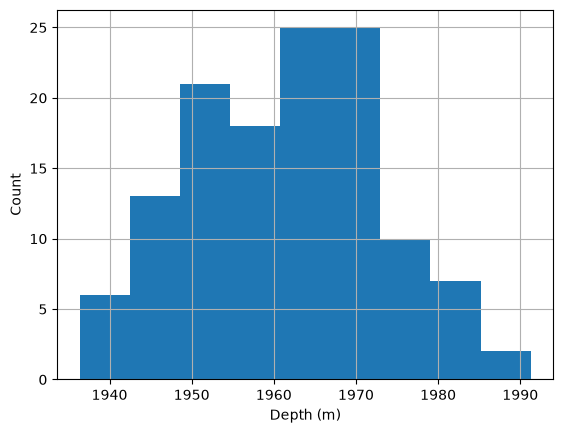

In [4]:
# Plot the histogram of Depth using Pandas functionalities
ax = data['Depth'].hist(bins='auto')
# Set some legend elements
ax.set(xlabel='Depth (m)', ylabel='Count');

The distribution shows a bell shape similar to a normal distribution, which is good: some statistical and geostatistical methods used in geomodeling assume that the data are normally distributed, and not fulfilling this assumption can lead to poor predictions. If you encounter a non-Gaussian distribution, you'll need to transform the data to make them normally distributed, but we'll come back to that in another notebook. For now take a look at the data in space: 

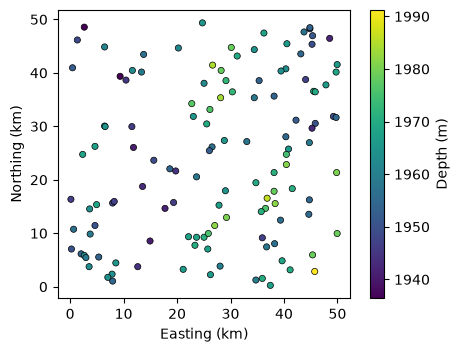

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the wells (topview) colored by depth
sc = ax.scatter(data['Easting'], data['Northing'], c=data['Depth'],
                s=20, edgecolors='k', lw=0.5)
# Set some legend elements
fig.colorbar(sc, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)', aspect='equal');

You can see that some samples are clustered, which can bias some summary statistics like the mean or the covariance. In such cases you can apply declustering techniques, but for now let's keep it simple and move on to some simple spatial predictions.

**Question 1:**  
What can lead well data to be clustered in space?

:::{dropdown} Хариулт
Wells are expensive, so they aren't drilled randomly: they usually target specific structures, e.g., permeable deposits. As multiple wells can target the same structure, for instance to maximize production, this leads to clustering. Well data are also much more densely sampled vertically than horizontally, which is another form of clustering.
:::

## 3. Spatial interpolations

Now that you have the data, you can move to the actual work: interpolating the top horizon. This means predicting the depth of the horizon over the entire domain of interest, so away from the wells. The goal is then to find a function $f$ so that:
$$
    \hat{y}(\mathbf{x_0}) = f(y(\mathbf{x}))
$$
Where:
 * $y$ is the variable of interest (here the depth).
 * $\hat{y}$ is the prediction of the variable of interest.
 * $\mathbf{x_0}$ is the coordinate of the unsampled location where we want to predict.
 * $\mathbf{x}$ are the coordinates of the locations where we have some data, here at the wells.

Multiple algorithms can be used to find $f$. Traditionally, geomodeling uses geostatistical methods that are based on a linear combination of the data, like so:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
Where:
 * $k$ is the number of data to consider in the prediction. If $k$ is less than the number of data samples, only the $k$-closest samples are considered.
 * $\mathbf{x_i}$ is the coordinate of the location of data sample $i$.
 * $\lambda_i$ is a weight associated to data sample $i$.

The only difference between those methods is how the weights $\lambda_i$ are computed.

Let's start by defining some basic variables. To make things simpler, you can extract the inputs `X` and the output `y` from the data:

In [6]:
X = data[['Easting', 'Northing']].to_numpy()
y = data['Depth'].to_numpy()

Then you need to define the locations where you want predictions. Usually those locations lie on a grid. Remember the context: the domain is 50 by 50 km, and the bottom left corner of the grid should be at (0, 0).

Here you can just use a regular grid of 200 by 200 cells. This means that the size of each cell will be 0.25 by 0.25 km. So to get the bottom left corner at (0, 0), you need the center of the bottom left cell to be at (0.125, 0.125).

Now that you have the basics sorted, you can use NumPy's function `meshgrid` to create the regular grid:

In [7]:
X_pred = np.meshgrid(np.linspace(0.125, 49.875, 200),
                     np.linspace(0.125, 49.875, 200))

If you check `X_pred`, you'll see that it is a tuple of two NumPy arrays. To make predictions, you will first use the Python package scikit-learn, which requires a 2D array as input. So first you need to stack the two arrays together:

In [8]:
X_pred = np.stack(X_pred, axis=-1)

In [9]:
X_pred.shape

(200, 200, 2)

Scikit-learn only accepts tabular data as input, so you need to flatten your grid, and you'll have to unflatten the predictions.

In [10]:
X_pred = X_pred.reshape(-1, 2)

In [11]:
X_pred.shape

(40000, 2)

Now you are ready to make predictions, first with the simplest approach possible: a nearest-neighbor interpolation. Remember that predictions are a linear combination of the data:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
In the case of a nearest-neighbor interpolation, each prediction is the value of the closest data point and we have:
$$
\begin{align}
    \lambda_i & = \frac{1}{k} \\[0.6em]
    k & = 1 \\
\end{align}
$$

In scikit-learn you can obtain that by using a `KNeighborsRegressor` and setting the parameter `n_neighbors` to 1:

In [12]:
estimator = KNeighborsRegressor(n_neighbors=1)

Now you need to call the function `fit` to pass on the data:

In [13]:
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


And you can predict the depth over all the cells of the grid:

In [14]:
y_pred = estimator.predict(X_pred)

Remember that you had to flatten the inputs? So now you need to unflatten the output to the grid dimensions:

In [15]:
y_pred = y_pred.reshape(200, 200)

And you can plot the result:

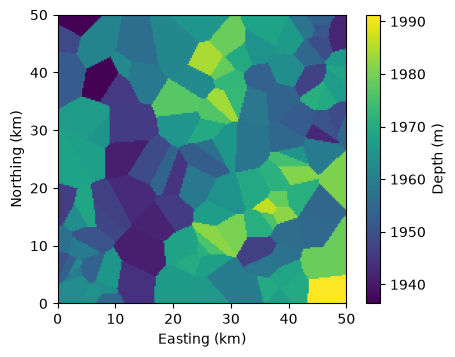

In [16]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');

**Question 2:**  
What do you think of those predictions?

:::{dropdown} Хариулт
They extend the data, with high jumps that are unrealistic.
:::

**Question 3:**  
Now do the same thing but with $k$ equal to the number of data. You can group some steps in a single cell to simplify the notebook.

:::{dropdown} Код харах
```python
estimator = KNeighborsRegressor(n_neighbors=127)
estimator.fit(X, y)
```
:::

In [17]:
estimator = KNeighborsRegressor(n_neighbors=127)
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",127
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


:::{dropdown} Код харах
```python
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)
```
:::

In [18]:
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)

:::{dropdown} Код харах
```python
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');
```
:::

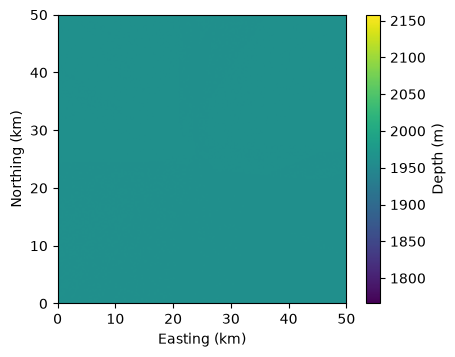

In [19]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');

**Question 4:**  
What do you think of those predictions?

:::{dropdown} Хариулт
They are all the same, since we use all the data with the same weights.
:::

To get better predictions, you need to add a degree of complexity. Remember Tobler's first law of geography? Let's use it to compute weights that vary with distance, which gives us:
$$
    \hat{y}(\mathbf{x_0}) = \sum_{i=1}^{k} \lambda_i y(\mathbf{x_i})
$$
With:
$$\begin{align}
    \lambda_i & = \frac{d(\mathbf{x_0}, \mathbf{x_i})^{-q}}{\sum_{i=1}^{k}d(\mathbf{x_0}, \mathbf{x_i})^{-q}} \\[0.6em]
    d(\mathbf{x_0}, \mathbf{x_i}) & = \sqrt{\sum_{j=1}^{n}(x_{0,j} - x_{i,j})^2} \\
    k & = 127 \\
\end{align}
$$
Where:
 * $q$ is the power parameter, which controls the influence of the data samples. It is commonly equal to 2.
 * $d$ is the Euclidean distance.
 * $n$ is the number of dimensions of the coordinates (here 2).

In geostatistics, this method is called inverse distance weighting (IDW). In machine learning, it is a special case of the k-nearest-neighbors regression that you've been using.

**Question 5:**  
Now make some new predictions by keeping $k$ equal to the number of data and using the value `'distance'` for the parameter `weights` of `KNeighborsRegressor`.

:::{dropdown} Код харах
```python
estimator = KNeighborsRegressor(n_neighbors=127, weights='distance')
estimator.fit(X, y)
```
:::

In [20]:
estimator = KNeighborsRegressor(n_neighbors=127, weights='distance')
estimator.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",127
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


:::{dropdown} Код харах
```python
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)
```
:::

In [21]:
y_pred = estimator.predict(X_pred)
y_pred = y_pred.reshape(200, 200)

:::{dropdown} Код харах
```python
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');
```
:::

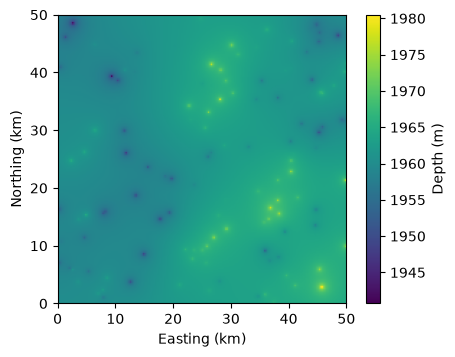

In [22]:
fig, ax = plt.subplots(figsize=(5, 3.75))

# Plot the predictions
im = ax.imshow(y_pred, origin='lower', extent=(0., 50., 0., 50.))
# Set some legend elements
fig.colorbar(im, ax=ax, label='Depth (m)')
ax.set(xlabel='Easting (km)', ylabel='Northing (km)');

**Question 6:**  
What do you think of those predictions?

:::{dropdown} Хариулт
They are smoother and more plausible, except for pikes around the data and little variability away from the data.
:::

:::{note} Sidenote

The predictions you just made are based on $q$ = 1. This often leads to spiky results, so $q$ = 2 is favored to smooth the predictions. To change $q$ in scikit-learn you can use the following code:
<pre><code>def inverse_distance_weighting(x, q=2):
    return 1. / x**q
estimator = KNeighborsRegressor(n_neighbors=140, weights=inverse_distance_weighting)</code></pre>
:::

:::{note} Sidenote

You can use any statistical or machine learning technique to predict depth from the coordinates. So using the same basic code you just used, you can use any algorithm for regression in scikit-learn, including neural networks for instance.
:::

In the next lessons, you'll see other approaches for predicting horizons and other geological structures.

:::{include} ../_attribution.md
:::